# UNSW-NB15 Membership Inference Attack (MIA): Random Forest Model Training

## Overview
This notebook trains a supervised **Random Forest** classifier as a **Membership Inference Attack (MIA)** attack model:
- **Target IDS Context**: The victim model is an AdaBoost Intrusion Detection System trained on the UNSW-NB15 benchmark dataset.
- **Attacker Objective**: Determine whether a given network connection record was used in the training set of the target IDS model (`is_member = 1`) or held out in the test set (`is_member = 0`).
- **MIA Training Dataset**: Loaded from `datasets/UNSW-NB15_MIA/train.csv` ($N = 175,217$ samples, 80% partition).
- **Attacker Feature Space**:
  - `class_prob`: Target model prediction confidence ($\max(P(\text{Normal}), P(\text{Attack}))$).
  - `predicted_class`: Target model predicted traffic category (`Benign`, `DoS`, `Generic`, `Exploits`, etc.).
  - `is_attack`: Binary ground-truth traffic indicator ($0 = \text{Benign}, 1 = \text{Attack}$).
- **Categorical Feature Encoding**: Encodes `predicted_class` using `OneHotEncoder` fitted strictly on the MIA training set.
- **Attacker Model Fitting**: Fits `RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42)`.
- **Model Artifact Export**: Serializes the trained classifier, encoder, and metadata to `models/MIA/random_forest/{timestamp}/`.

In [1]:
import os
import json
import pickle
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("MIA training environment and libraries loaded successfully.")

MIA training environment and libraries loaded successfully.


## 1. Load MIA Training Dataset

Load the pre-split MIA training dataset from `datasets/UNSW-NB15_MIA/train.csv` generated by `notebooks/data_processing/mia_dataset.ipynb`.

In [2]:
# Resolve path to datasets/UNSW-NB15_MIA directory
base_dir = Path.cwd()
possible_dirs = [
    base_dir / '../../datasets/UNSW-NB15_MIA',
    base_dir / 'datasets/UNSW-NB15_MIA',
    Path(r'd:/Swinburne Courses/Project A/datasets/UNSW-NB15_MIA')
]

mia_dir = next((d.resolve() for d in possible_dirs if d.resolve().exists()), None)
if mia_dir is None:
    raise FileNotFoundError("Could not locate datasets/UNSW-NB15_MIA directory.")

print(f"Loading MIA training dataset from: {mia_dir.resolve()}")
t0 = time.time()
train_df = pd.read_csv(mia_dir / 'train.csv')
print(f"Loaded train.csv in {time.time()-t0:.2f} s: {len(train_df):,} rows x {train_df.shape[1]} columns")

# Summary of training set distribution
member_count = (train_df['is_member'] == 1).sum()
non_member_count = (train_df['is_member'] == 0).sum()

summary_table = pd.DataFrame({
    'Metric': [
        'Total Training Samples',
        'Member Samples (is_member=1)',
        'Non-Member Samples (is_member=0)',
        'Member Ratio (%)',
        'Attack Samples (is_attack=1)',
        'Benign Samples (is_attack=0)',
        'Unique Predicted Classes'
    ],
    'Value': [
        f"{len(train_df):,}",
        f"{member_count:,}",
        f"{non_member_count:,}",
        f"{member_count / len(train_df) * 100:.2f}%",
        f"{(train_df['is_attack'] == 1).sum():,}",
        f"{(train_df['is_attack'] == 0).sum():,}",
        f"{train_df['predicted_class'].nunique()}"
    ]
})
display(summary_table)

Loading MIA training dataset from: D:\Swinburne Courses\Project A\datasets\UNSW-NB15_MIA
Loaded train.csv in 0.05 s: 175,217 rows x 4 columns


,Metric,Value
0,Total Training Samples,"175,217"
1,Member Samples (is_member=1),"144,296"
2,Non-Member Samples (is_member=0),"30,921"
3,Member Ratio (%),82.35%
4,Attack Samples (is_attack=1),"111,977"
5,Benign Samples (is_attack=0),"63,240"
6,Unique Predicted Classes,10


## 2. Feature & Target Separation

Separate the attacker's input features from the target membership label:
- **Feature Set ($X$)**: `class_prob`, `predicted_class`, `is_attack`.
- **Target ($y$)**: `is_member` (1 = Training sample, 0 = Testing sample).

In [3]:
target_col = 'is_member'
feature_cols = ['class_prob', 'predicted_class', 'is_attack']

X_raw = train_df[feature_cols].copy()
y_train = train_df[target_col].values

print(f"Target column:    {target_col}")
print(f"Feature columns:  {feature_cols}")
print(f"X_raw shape:      {X_raw.shape}")
print(f"y_train shape:    {y_train.shape}")
print(f"\nSample records:")
display(X_raw.head(5))

Target column:    is_member
Feature columns:  ['class_prob', 'predicted_class', 'is_attack']
X_raw shape:      (175217, 3)
y_train shape:    (175217,)

Sample records:


,class_prob,predicted_class,is_attack
0,0.701882,Generic,1
1,0.671561,Benign,0
2,0.510452,Benign,0
3,0.517825,Benign,0
4,0.628008,Exploits,1


## 3. Categorical Feature Encoding

Encode the categorical feature `predicted_class` using `OneHotEncoder` fitted strictly on the training set with `handle_unknown='ignore'` to support unseen labels gracefully.

In [4]:
# Initialize and fit OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
cat_encoded = encoder.fit_transform(X_raw[['predicted_class']])
cat_feature_names = list(encoder.get_feature_names_out(['predicted_class']))

print(f"Fitted OneHotEncoder on {len(encoder.categories_[0])} categories:")
print(f"  Categories: {list(encoder.categories_[0])}")

# Combine numerical features and one-hot encoded categories
numerical_cols = ['class_prob', 'is_attack']
X_train_encoded = np.column_stack([X_raw[numerical_cols].values, cat_encoded])
all_feature_names = numerical_cols + cat_feature_names

print(f"\nTotal Encoded Features: {len(all_feature_names)}")
print(f"Feature Names: {all_feature_names}")
print(f"X_train_encoded shape: {X_train_encoded.shape}")

Fitted OneHotEncoder on 10 categories:
  Categories: ['Analysis', 'Backdoor', 'Benign', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']

Total Encoded Features: 12
Feature Names: ['class_prob', 'is_attack', 'predicted_class_Analysis', 'predicted_class_Backdoor', 'predicted_class_Benign', 'predicted_class_DoS', 'predicted_class_Exploits', 'predicted_class_Fuzzers', 'predicted_class_Generic', 'predicted_class_Reconnaissance', 'predicted_class_Shellcode', 'predicted_class_Worms']
X_train_encoded shape: (175217, 12)


## 4. Train Random Forest MIA Model

We train a **Random Forest Classifier** as the membership inference attack model:
- `n_estimators = 100`: Number of decision trees.
- `max_depth = 12`: Limits tree depth to control variance and prevent overfitting.
- `class_weight = 'balanced'`: Compensates for the 82%/18% membership imbalance.
- `random_state = RANDOM_STATE`: Ensures reproducibility.
- `n_jobs = -1`: Utilizes all available CPU cores for parallel training.

In [5]:
print("=== Training Random Forest MIA Model on UNSW-NB15 MIA Dataset ===")
rf_mia = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

t_start = time.time()
rf_mia.fit(X_train_encoded, y_train)
t_train = time.time() - t_start

print(f"Training completed in {t_train:.2f} seconds ({t_train/60:.2f} minutes).")
print(f"Number of Estimators:  {len(rf_mia.estimators_)}")
print(f"Classes:               {rf_mia.classes_}")
print(f"Model parameters:      max_depth={rf_mia.max_depth}, class_weight={rf_mia.class_weight}")

=== Training Random Forest MIA Model on UNSW-NB15 MIA Dataset ===


Training completed in 2.01 seconds (0.03 minutes).
Number of Estimators:  100
Classes:               [0 1]
Model parameters:      max_depth=12, class_weight=balanced


## 5. Attacker Feature Importance Analysis

Inspect which features provide the strongest signal for inferring target model membership.

=== MIA Feature Importances (Gini Impurity Reduction) ===


,Feature,Importance
0,class_prob,0.9581
1,predicted_class_DoS,0.0058
2,predicted_class_Fuzzers,0.0054
3,predicted_class_Backdoor,0.0051
4,predicted_class_Analysis,0.0044
5,predicted_class_Reconnaissance,0.0043
6,predicted_class_Generic,0.0041
7,predicted_class_Exploits,0.0040
8,predicted_class_Shellcode,0.0026
9,is_attack,0.0022


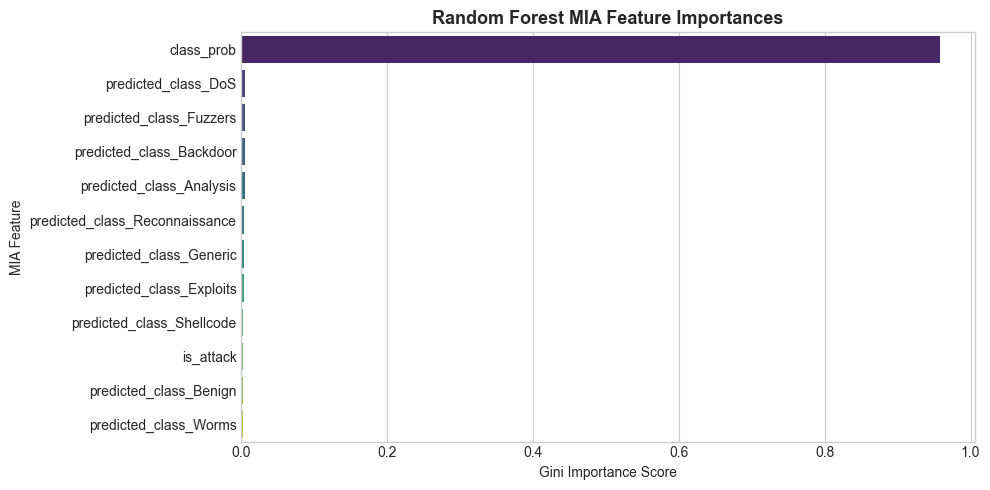

In [6]:
# Compute feature importances
importances = pd.Series(rf_mia.feature_importances_, index=all_feature_names).sort_values(ascending=False)

print("=== MIA Feature Importances (Gini Impurity Reduction) ===")
display(pd.DataFrame({'Feature': importances.index, 'Importance': importances.values}).style.format({'Importance': '{:.4f}'}))

# Visualize Feature Importances
plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title("Random Forest MIA Feature Importances", fontsize=13, fontweight='bold')
plt.xlabel("Gini Importance Score")
plt.ylabel("MIA Feature")
plt.tight_layout()
plt.show()

## 6. Export Trained Model Artifacts

Export the trained Random Forest MIA model, feature encoder, and training metadata to the project model registry under:
`models/MIA/random_forest/{timestamp}/`

Directory structure:
- `models/MIA/random_forest/{timestamp}/random_forest_model.pkl`: Serialized Random Forest classifier.
- `models/MIA/random_forest/{timestamp}/encoder.pkl`: Fitted OneHotEncoder for `predicted_class`.
- `models/MIA/random_forest/{timestamp}/metadata.json`: Hyperparameters, feature list, and training metadata.

In [7]:
# Resolve models directory
possible_models_dirs = [
    base_dir / '../../models',
    base_dir / 'models',
    Path(r'd:/Swinburne Courses/Project A/models')
]
models_root = next((d.resolve() for d in possible_models_dirs if d.resolve().exists()), None)
if models_root is None:
    raise FileNotFoundError("Could not locate models directory.")

# Model registry path: models/{IDS or MIA}/{model_name}/{timestamp}
timestamp_str = datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
model_category = "MIA"
model_name = "random_forest"
save_dir = models_root / model_category / model_name / timestamp_str
save_dir.mkdir(parents=True, exist_ok=True)

# 1. Export Random Forest model
model_file = save_dir / "random_forest_model.pkl"
with open(model_file, "wb") as f:
    pickle.dump(rf_mia, f)

# 2. Export OneHotEncoder
encoder_file = save_dir / "encoder.pkl"
with open(encoder_file, "wb") as f:
    pickle.dump(encoder, f)

# 3. Export metadata
metadata = {
    "model_category": model_category,
    "model_name": model_name,
    "timestamp": timestamp_str,
    "training_samples": len(X_train_encoded),
    "input_features": feature_cols,
    "encoded_features": all_feature_names,
    "target_column": target_col,
    "dataset_source": "datasets/UNSW-NB15_MIA/train.csv",
    "hyperparameters": {
        "n_estimators": rf_mia.n_estimators,
        "max_depth": rf_mia.max_depth,
        "class_weight": rf_mia.class_weight,
        "random_state": RANDOM_STATE
    },
    "training_time_seconds": round(t_train, 2),
    "feature_importances": importances.to_dict()
}

metadata_file = save_dir / "metadata.json"
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("=== MIA Model Successfully Exported ===")
print(f"Destination: {save_dir.resolve()}\n")
print(f"Files saved:")
print(f"  - Model:    {model_file.name} ({model_file.stat().st_size:,} bytes)")
print(f"  - Encoder:  {encoder_file.name} ({encoder_file.stat().st_size:,} bytes)")
print(f"  - Metadata: {metadata_file.name} ({metadata_file.stat().st_size:,} bytes)")

=== MIA Model Successfully Exported ===
Destination: D:\Swinburne Courses\Project A\models\MIA\random_forest\2026-09-30_19-53-53

Files saved:
  - Model:    random_forest_model.pkl (5,313,308 bytes)
  - Encoder:  encoder.pkl (694 bytes)
  - Metadata: metadata.json (1,688 bytes)
